In [9]:
# construct figures for monochromatic psf fisher information

import jax
import jax.numpy as np
import dLux as dl
import dLux.utils as dlu
import matplotlib.pyplot as plt
from matplotlib.style import use
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

In [2]:
diameter = 1.0
wavelength = 1e-6

flux = 1e6 # just a simply large number

source = dl.PointSource(position = np.zeros(2), flux=flux, wavelengths=np.array([wavelength]))

Nyq_factor = 4 # 4x oversample nyquist

# generate a very well sampled circle methinks
wf_npix = 2048
wf_oversample = 5

aperture = dlu.circular_aperture(wf_npix, diameter, wf_oversample)

layers = [
    (
        'aperture',
        dl.TransmissiveLayer(aperture, normalise=True)
    )
]

rmax = 10 # units lambda/D

fov = 2*wavelength/diameter*rmax # fov in radians. not radial, whole fov

psf_npix = int(np.ceil(2 * (2 * rmax) * Nyq_factor))

psf_pixel_scale = dlu.rad2arcsec(fov/psf_npix)

optics = dl.AngularOpticalSystem(
    wf_npix,
    diameter,
    layers,
    psf_npix,
    psf_pixel_scale,
    1
)

telescope = dl.Telescope(optics, source)

data = telescope.model()

In [3]:
# let us calculate fisher first.. then think about circular mask
from zodiax.diffops import hessian
def loss_fn(params, model, data):
    model = model.set(params)
    img = model.model()

    ny, nx = data.shape
    y, x = np.indices(data.shape)

    mask = (x - (nx - 1) / 2)**2 + (y - (ny - 1) / 2)**2 <= (min(nx, ny) / 2)**2

    loss = -np.where(mask, poisson_loglike_gamma(data, img), 0.0).sum()

    # loss = -poisson_loglike_gamma(data, img).sum()
    return loss

params = {
    'wavelengths':
    np.array([wavelength])
}

f = lambda params: loss_fn(params, telescope, data)

H, unflatten = hessian(f, params)

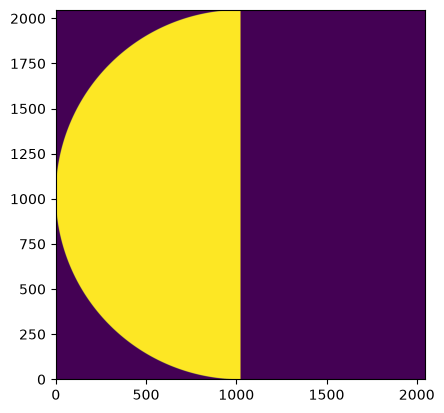

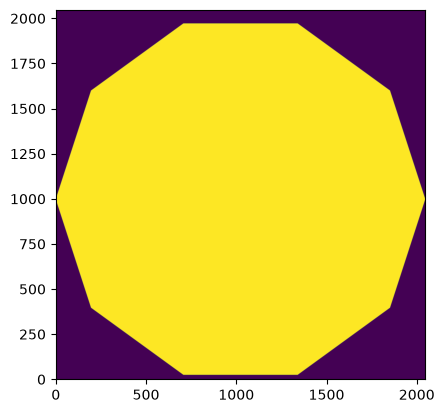

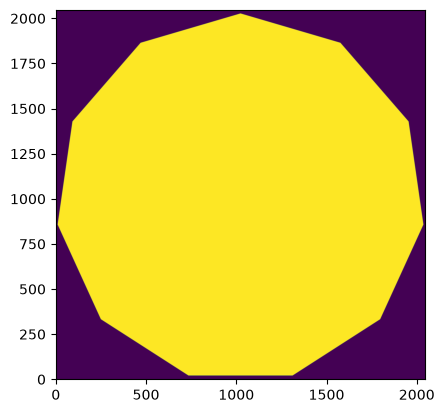

In [4]:
coords = dlu.pixel_coords(wf_npix*wf_oversample, diameter)

# square = (dlu.downsample(dlu.reg_polygon(coords, diameter/2, 5), wf_oversample, mean=True).T)[::-1,:]

# # just putting in a nicer spot
# tol = 1e-12

# mask = np.any(np.abs(square) > tol, axis=1)  # True for rows with any nonzero element

# nzero = len(square) if not mask.any() else np.argmax(mask)
# half = nzero // 2

# square = np.concatenate([square[half:], square[:half]], axis=0)

mask = np.arange(aperture.shape[1]) < aperture.shape[1] // 2
square = aperture * mask

square = aperture * mask



layers_square = [
    (
        'aperture',
        dl.TransmissiveLayer(square, normalise=True)
    )
]

# try webb and hst apertures I thinik
# wfc3 = np.load('wfc3_aperture_2048.npy')

wfc3 = (dlu.downsample(dlu.reg_polygon(coords, diameter/2, 10), wf_oversample, mean=True))[::-1,:]
# # just putting in a nicer spot
tol = 1e-12

mask = np.any(np.abs(wfc3) > tol, axis=1)  # True for rows with any nonzero element

nzero = len(wfc3) if not mask.any() else np.argmax(mask)
half = nzero // 2

wfc3 = np.concatenate([wfc3[half:], wfc3[:half]], axis=0)


layers_wfc3 = [
    (
        'aperture',
        dl.TransmissiveLayer(wfc3, normalise=True)
    )
]

# nircam = np.load('nircam_aperture_2048.npy')

nircam = (dlu.downsample(dlu.reg_polygon(coords, diameter/2, 11), wf_oversample, mean=True).T)[::-1,:]
# # just putting in a nicer spot
tol = 1e-12

mask = np.any(np.abs(nircam) > tol, axis=1)  # True for rows with any nonzero element

nzero = len(nircam) if not mask.any() else np.argmax(mask)
half = nzero // 2

nircam = np.concatenate([nircam[half:], nircam[:half]], axis=0)


layers_nircam = [
    (
        'aperture',
        dl.TransmissiveLayer(nircam, normalise=True)
    )
]

plt.imshow(square)
plt.show()

plt.imshow(wfc3)
plt.show()

plt.imshow(nircam)
plt.show()

In [5]:
# ok so that works. now for different values of rmax
rmaxes = np.logspace(0, 2, 50)

Hs_airy = []
Hs_square = []
Hs_wfc3 = []
Hs_nircam = []

for rmax in rmaxes:
    print(rmax)
    fov = 2*wavelength/diameter*rmax # fov in radians. not radial, whole fov

    psf_npix = int(np.ceil(2 * (2 * rmax) * Nyq_factor))

    psf_pixel_scale = dlu.rad2arcsec(fov/psf_npix)

    optics = dl.AngularOpticalSystem(
        wf_npix,
        diameter,
        layers,
        psf_npix,
        psf_pixel_scale,
        1
    )

    telescope = dl.Telescope(optics, source)

    data = telescope.model()
    f = lambda params: loss_fn(params, telescope, data)
    H, unflatten = hessian(f, params)
    H = H.squeeze()
    Hs_airy.append(H)

    # SQUARE STUFF
    optics_square = dl.AngularOpticalSystem(
        wf_npix,
        diameter,
        layers_square,
        psf_npix,
        psf_pixel_scale,
        1
    )

    telescope_square = dl.Telescope(optics_square, source)

    data = telescope_square.model()
    f = lambda params: loss_fn(params, telescope_square, data)
    H, unflatten = hessian(f, params)
    H = H.squeeze()
    Hs_square.append(H)

    # HUBBLE STUFF
    optics_wfc3 = dl.AngularOpticalSystem(
        wf_npix,
        diameter,
        layers_wfc3,
        psf_npix,
        psf_pixel_scale,
        1
    )

    telescope_wfc3 = dl.Telescope(optics_wfc3, source)

    data = telescope_wfc3.model()
    f = lambda params: loss_fn(params, telescope_wfc3, data)
    H, unflatten = hessian(f, params)
    H = H.squeeze()
    Hs_wfc3.append(H)

    # NIRCAM STUFF
    optics_nircam = dl.AngularOpticalSystem(
        wf_npix,
        diameter,
        layers_nircam,
        psf_npix,
        psf_pixel_scale,
        1
    )

    telescope_nircam = dl.Telescope(optics_nircam, source)

    data = telescope_nircam.model()
    f = lambda params: loss_fn(params, telescope_nircam, data)
    H, unflatten = hessian(f, params)
    H = H.squeeze()
    Hs_nircam.append(H)


1.0
1.0985411419875581
1.2067926406393286
1.3257113655901092
1.4563484775012439
1.599858719606058
1.7575106248547918
1.93069772888325
2.120950887920191
2.329951810515372
2.5595479226995357
2.8117686979742302
3.088843596477481
3.393221771895328
3.72759372031494
4.094915062380425
4.498432668969445
4.941713361323834
5.428675439323859
5.963623316594643
6.551285568595508
7.196856730011519
7.906043210907698
8.685113737513525
9.54095476349994
10.481131341546858
11.513953993264469
12.648552168552959
13.894954943731374
15.264179671752334
16.768329368110074
18.420699693267153
20.235896477251565
22.229964825261945
24.42053094548651
26.826957952797247
29.4705170255181
32.374575428176435
35.564803062231285
39.06939937054615
42.91934260128776
47.14866363457392
51.7947467923121
56.89866029018296
62.505519252739695
68.66488450042998
75.43120063354615
82.86427728546842
91.02981779915217
100.0


In [6]:
# defining analytic result
def wl_fisher_airy(wavelength, flux, diameter, R):
    fisher = 8*flux*diameter*R/(wavelength**3)
    return fisher

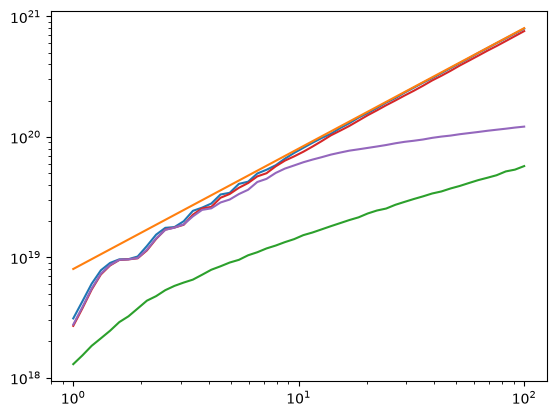

In [7]:
plt.loglog(rmaxes, Hs_airy)
plt.loglog(rmaxes, wl_fisher_airy(wavelength, flux, diameter, rmaxes*wavelength/diameter))
plt.loglog(rmaxes, Hs_square)
plt.loglog(rmaxes, Hs_wfc3)
plt.loglog(rmaxes, Hs_nircam)
plt.show()

/Library/TeX/texbin/latex


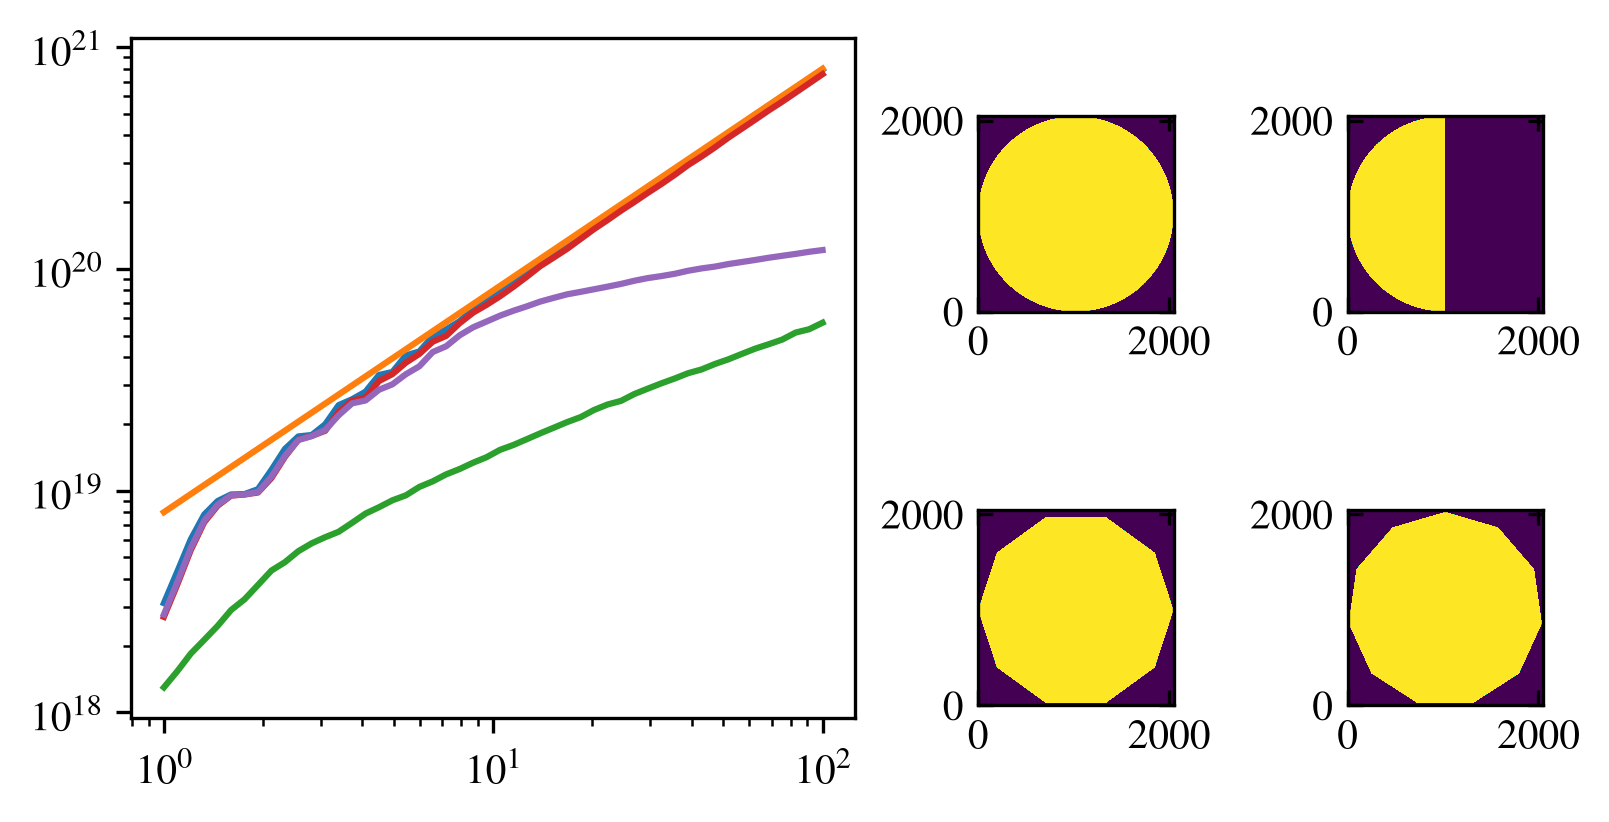

In [10]:
# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 10,
})

plt.rcParams["figure.dpi"] = 300
# fig_width = 379.41753 / 72.27 # = 5.25
fig_width = 5.25

fig = plt.figure(
    figsize=(fig_width, 0.5 * fig_width),
    constrained_layout=True,
)

# Outer layout: large line plot + right-hand image block
outer = fig.add_gridspec(
    1, 2,
    width_ratios=[1, 1],
)

ax = fig.add_subplot(outer[0, 0])

# Divide the right-hand side into four square panels
right = outer[0, 1].subgridspec(
    2, 2,
    wspace=0.05,
    hspace=0.05,
)

ax_im1 = fig.add_subplot(right[0, 0])
ax_im2 = fig.add_subplot(right[0, 1])
ax_im3 = fig.add_subplot(right[1, 0])
ax_im4 = fig.add_subplot(right[1, 1])

# Left panel
# ax.loglog(x, y)
ax.loglog(rmaxes, Hs_airy)
ax.loglog(rmaxes, wl_fisher_airy(wavelength, flux, diameter, rmaxes*wavelength/diameter))
ax.loglog(rmaxes, Hs_square)
ax.loglog(rmaxes, Hs_wfc3)
ax.loglog(rmaxes, Hs_nircam)

# Right panels
image_axes = [ax_im1, ax_im2, ax_im3, ax_im4]
arrays = [aperture, square, wfc3, nircam]

for ax_im, array in zip(image_axes, arrays):
    ax_im.imshow(
        array,
        origin="lower",
        interpolation="none",
        aspect="equal",
    )
    ax_im.set_box_aspect(1)  # makes the axes themselves square
    ax_im.tick_params(
        axis="both",
        which="both",
        direction="in",
        top=True,
        right=True,
    )

In [11]:
Hs_analytic = wl_fisher_airy(wavelength, flux, diameter, rmaxes*wavelength/diameter)

In [12]:
dimless_fac = wavelength**2/flux

In [13]:
dimless_fac

1e-18

In [14]:
rmaxes_analytic = np.logspace(-0.2, 2.2, 5)
Hs_analytic = wl_fisher_airy(wavelength, flux, diameter, rmaxes_analytic*wavelength/diameter)

In [15]:
vmin

-3.0

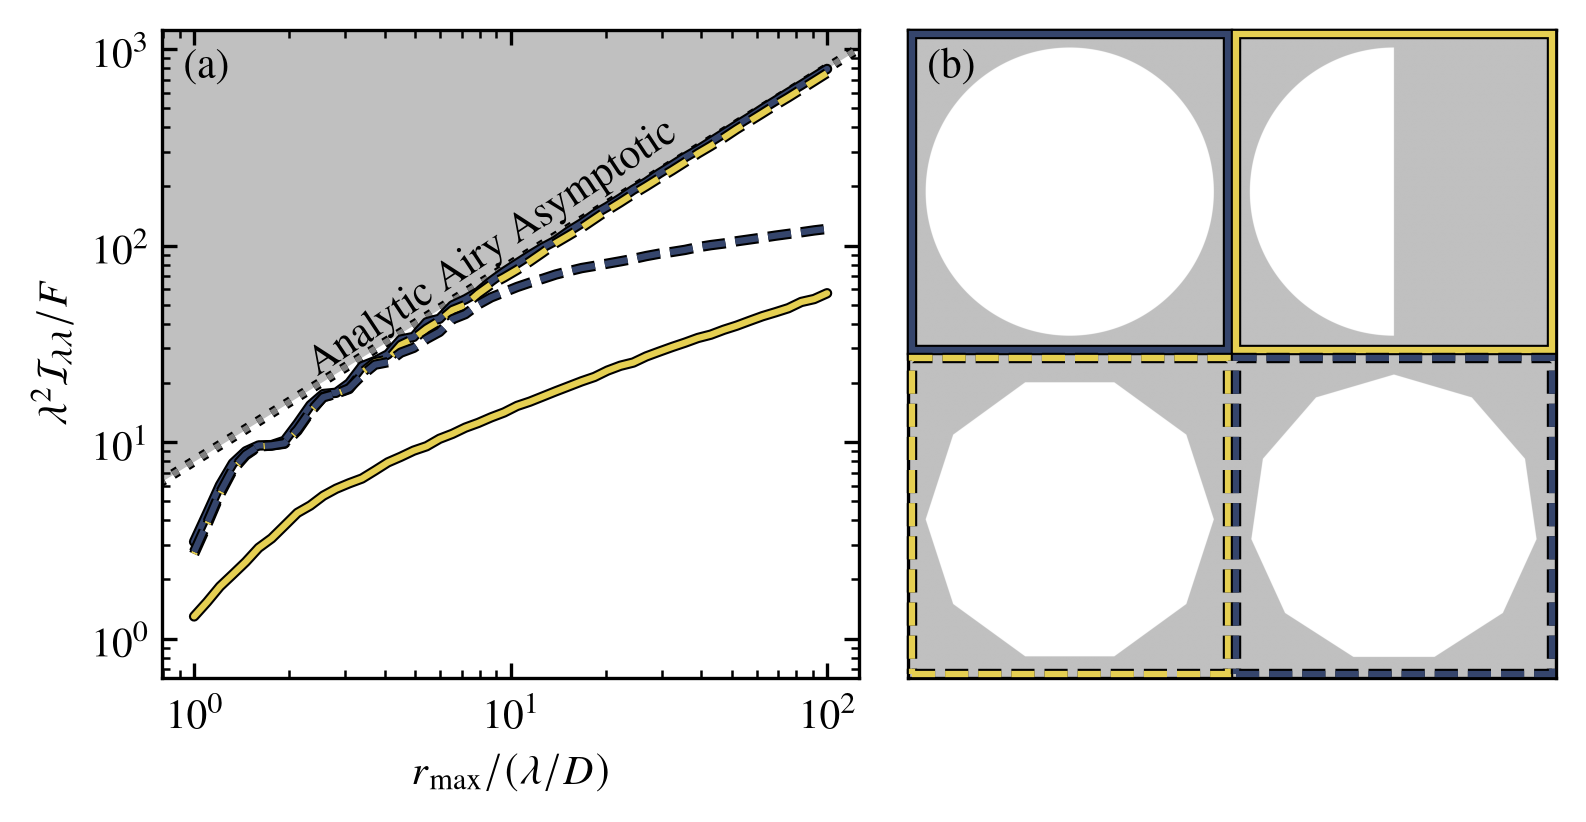

In [16]:
import matplotlib.patheffects as pe
import numpy as onp

path_effects = [
    pe.Stroke(linewidth=2.5, foreground="k"),
    pe.Normal(),
]

cmap = plt.colormaps['cividis']
color_1 = cmap(0.2)
color_2 = cmap(0.9)

vmax = 1.0
u0 = 0.75 # zero will use gray-cmap value at 75%

vmin = -(u0 / (1 - u0)) * vmax
zero_gray = plt.colormaps["gray"](u0)

border_pad = 128  # border width in pixels

wfc3_pad, nircam_pad, aperture_pad, square_pad = [
    np.pad(a, border_pad, constant_values=0)
    for a in (wfc3, nircam, aperture, square)
]

combined = np.block([
    [wfc3_pad, nircam_pad],
    [aperture_pad, square_pad],
])

fig, (ax, ax_im) = plt.subplots(
    1, 2,
    figsize=(fig_width, 0.5 * fig_width),
    gridspec_kw={"width_ratios": [1, 1]},
    constrained_layout=True,
)

ys_analytic = np.array(Hs_analytic)*dimless_fac
ys_airy = np.array(Hs_airy)*dimless_fac
ys_square = np.array(Hs_square)*dimless_fac
ys_wfc3 = np.array(Hs_wfc3)*dimless_fac
ys_nircam = np.array(Hs_nircam)*dimless_fac

ax.loglog(rmaxes_analytic, ys_analytic,
          path_effects=path_effects, ls=':',
          color='0.5')
ax.loglog(rmaxes, ys_airy,
          path_effects=path_effects,
          color=color_1, label=r'$\mathcal{I}_{\lambda \lambda} \sim 7.9 r_{\max}$', solid_capstyle='round')
ax.loglog(rmaxes, ys_wfc3,
          path_effects=path_effects,
          color=color_2, ls='--', label=r'$\mathcal{I}_{\lambda \lambda} \sim 7.8 r_{\max}$')
ax.loglog(rmaxes, ys_square,
          path_effects=path_effects,
          color=color_2, label=r'$\mathcal{I}_{\lambda \lambda} \sim 5.1 \log r_{\max}$', solid_capstyle='round')
ax.loglog(rmaxes, ys_nircam,
          path_effects=path_effects,
          color=color_1, ls='--', label=r'$\mathcal{I}_{\lambda \lambda} \sim 5.6 r_{\max}$')

ax.fill_between(
    rmaxes_analytic,
    ys_analytic,
    ax.get_ylim()[1],
    color=zero_gray,
    alpha=1.0,
    linewidth=0,
    zorder=0,
)

ax.tick_params(axis='both',
               which='both',
               direction='in',
               top=True,
               right=True)

ax.set_ylim(10**(-0.2), 10**3.1)
ax.set_xlim(10**(-0.1), 10**2.1)

ax.set_xlabel(r'$r_{\max}/(\lambda/D)$')
ax.set_ylabel(r'$\lambda^2 \mathcal{I}_{\lambda \lambda}/F$')

ax.text(
    0.03, 0.97,
    r'(a)',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='k'
)

ax.text(
    0.2, 0.87,
    r'Analytic Airy Asymptotic',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='k',
    rotation=33.5,
)

# ax.legend(frameon=False, markerfirst=False, handlelength=1.0)

ax_im.imshow(
    combined,
    origin="lower",
    aspect="equal",
    interpolation="auto",
    cmap='gray',
    vmin=vmin,
    vmax=vmax
)

ax_im.text(
    0.03, 0.97,
    r'(b)',
    transform=ax_im.transAxes,
    ha='left',
    va='top',
    color='k'
)

ax_im.set_xticks([])
ax_im.set_yticks([])

from matplotlib.patches import Rectangle

pad = 0.00644 # in axes-fraction units

path_effects_thick = [
    pe.Stroke(linewidth=2.5, foreground="k"),
    pe.Normal(),
]

rect_kw = dict(
    fill=False,
    lw=1.5,
    transform=ax_im.transAxes,
    clip_on=False,
    zorder=10,
    path_effects=path_effects_thick,
    # capstyle='round',
)

# In the displayed image:
# top-left  = aperture   -> Airy      -> color_1, solid
# top-right = square     -> square    -> color_2, solid
# bottom-left = wfc3     -> WFC3      -> color_2, dashed
# bottom-right = nircam  -> NIRCam    -> color_1, dashed

ax_im.add_patch(Rectangle(
    (0.00 + pad, 0.50 + pad), 0.50 - 2*pad, 0.50 - 2*pad,
    edgecolor=color_1, linestyle='-', **rect_kw
))

ax_im.add_patch(Rectangle(
    (0.50 + pad, 0.50 + pad), 0.50 - 2*pad, 0.50 - 2*pad,
    edgecolor=color_2, linestyle='-', **rect_kw
))

ax_im.add_patch(Rectangle(
    (0.00 + pad, 0.00 + pad), 0.50 - 2*pad, 0.50 - 2*pad,
    edgecolor=color_2, linestyle='--', **rect_kw
))

ax_im.add_patch(Rectangle(
    (0.50 + pad, 0.00 + pad), 0.50 - 2*pad, 0.50 - 2*pad,
    edgecolor=color_1, linestyle='--', **rect_kw
))

# plt.savefig('monofigureF.png', dpi=300)
plt.show()

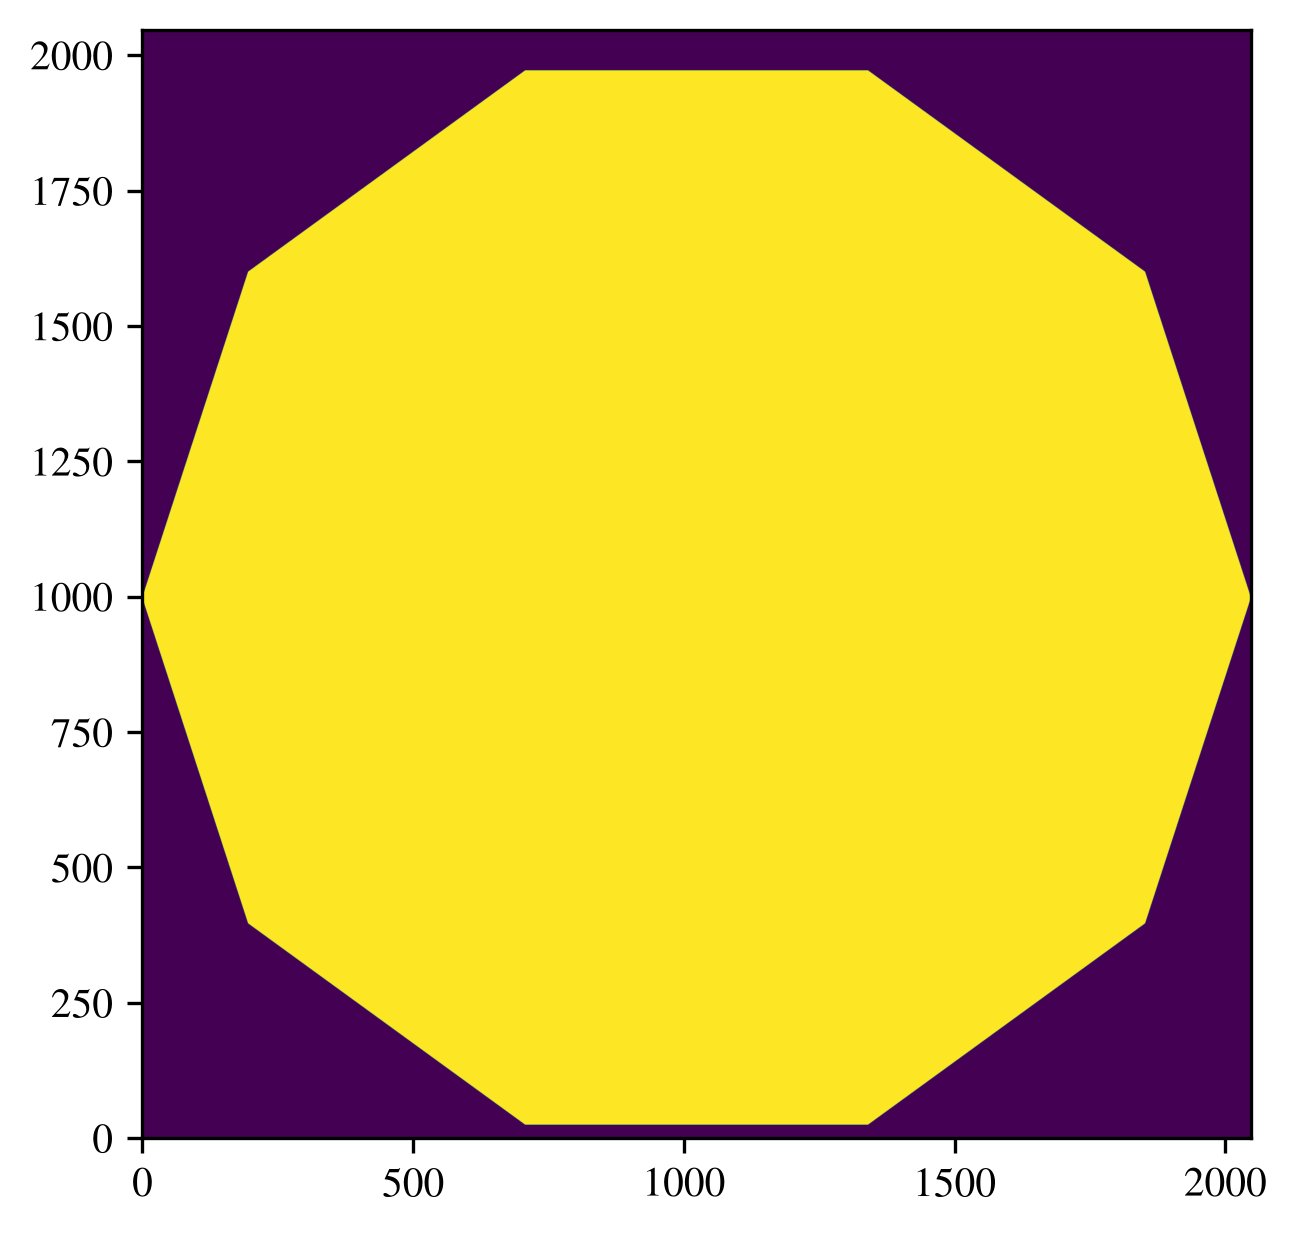

In [18]:
plt.imshow(wfc3)

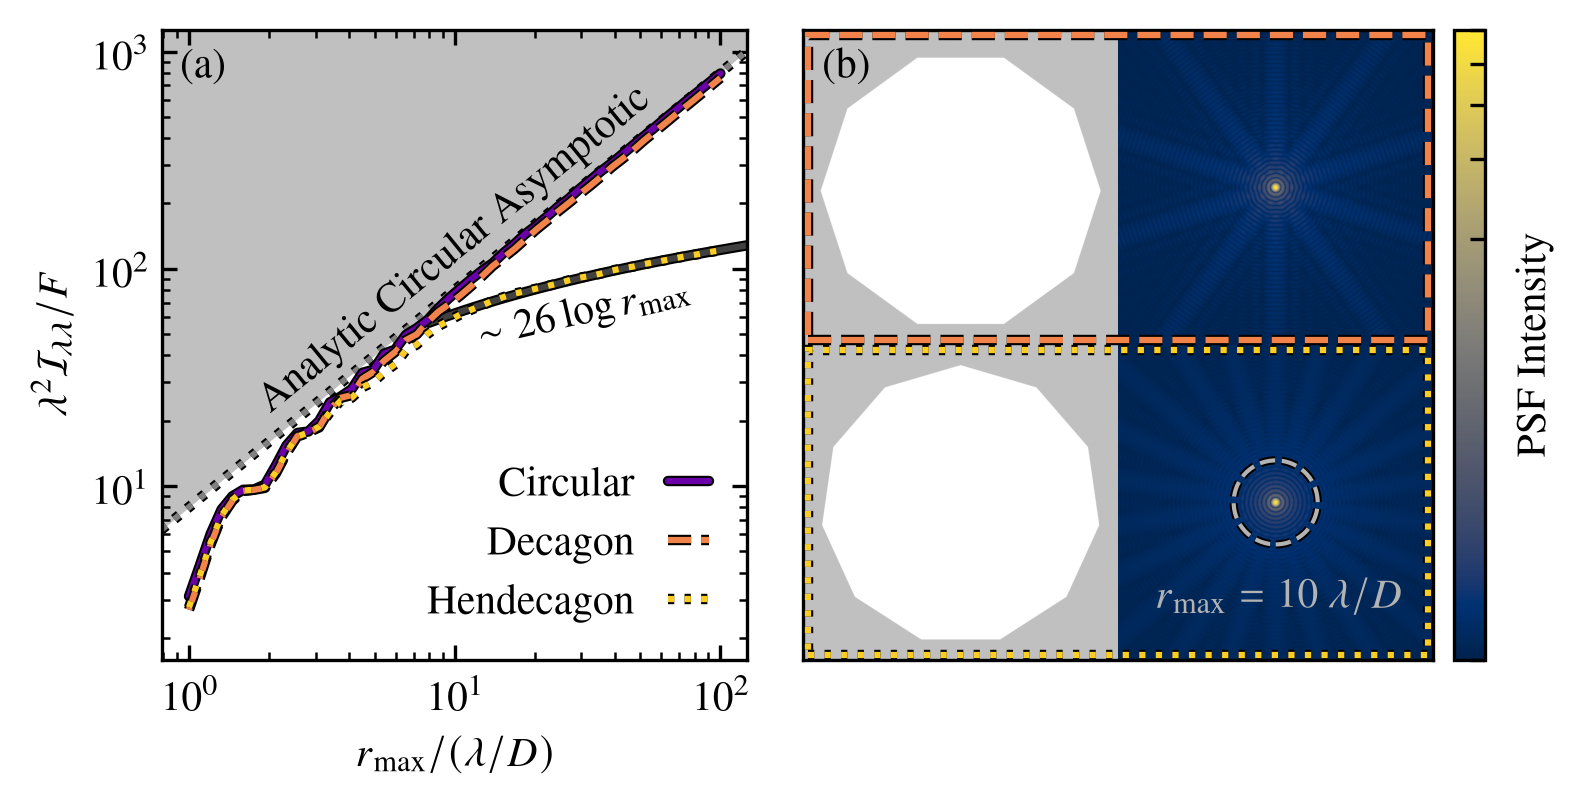

In [ ]:
import matplotlib.patheffects as pe
import numpy as onp

path_effects = [
    pe.Stroke(linewidth=2.5, foreground="k"),
    pe.Normal(),
]

cmap = plt.colormaps['plasma']
color_1 = cmap(0.2)
color_2 = cmap(0.7)
color_3 = cmap(0.9)

vmax = 1.0
u0 = 0.75 # zero will use gray-cmap value at 75%

vmin = -(u0 / (1 - u0)) * vmax
zero_gray = plt.colormaps["gray"](u0)

border_pad = 128  # border width in pixels

wfc3_pad, nircam_pad, aperture_pad, square_pad = [
    np.pad(a, border_pad, constant_values=0)
    for a in (wfc3, nircam, aperture, square)
]

combined = np.block([
    [wfc3_pad, nircam_pad],
    [aperture_pad, square_pad],
])

fig, (ax, ax_im) = plt.subplots(
    1, 2,
    figsize=(fig_width, 0.5 * fig_width),
    gridspec_kw={"width_ratios": [0.85, 1],#},
                 "wspace": 0.08},
    # constrained_layout=True,
)
fig.subplots_adjust(
    left=0.10,
    right=0.94,
    bottom=0.18,
    top=0.98,
)

ys_analytic = np.array(Hs_analytic)*dimless_fac
ys_airy = np.array(Hs_airy)*dimless_fac
ys_square = np.array(Hs_square)*dimless_fac
ys_wfc3 = np.array(Hs_wfc3)*dimless_fac
ys_nircam = np.array(Hs_nircam)*dimless_fac

ax.loglog(
    rmaxes_new,
    ys_nircam_fit,
    color='0.25',
    ls='-',
    path_effects=path_effects, 
    solid_capstyle='round'
    # lw=1.5,
    # label=rf'Fit: ${a_log:.2f}\log r_{{\max}} + {b_log:.2f}$'
)

ax.loglog(rmaxes_analytic, ys_analytic,
          path_effects=path_effects, ls=':',
          color='0.5')
ax.loglog(rmaxes, ys_airy,
          path_effects=path_effects,
          color=color_1, label=r'Circular', solid_capstyle='round')
ax.loglog(rmaxes, ys_wfc3,
          path_effects=path_effects,
          color=color_2, ls='--', label=r'Decagon')
# ax.loglog(rmaxes, ys_square,
#           path_effects=path_effects,
#           color=color_2, label=r'$\mathcal{I}_{\lambda \lambda} \sim 5.1 \log r_{\max}$', solid_capstyle='round')



ax.loglog(rmaxes, ys_nircam,
          path_effects=path_effects,
          color=color_3, ls=':', label=r'Hendecagon')

ax.fill_between(
    rmaxes_analytic,
    ys_analytic,
    ax.get_ylim()[1],
    color=zero_gray,
    alpha=1.0,
    linewidth=0,
    zorder=0,
)

ax.tick_params(axis='both',
               which='both',
               direction='in',
               top=True,
               right=True)

ax.set_ylim(10**(0.2), 10**3.1)
ax.set_xlim(10**(-0.1), 10**2.1)

ax.set_xlabel(r'$r_{\max}/(\lambda/D)$')
ax.set_ylabel(r'$\lambda^2 \mathcal{I}_{\lambda \lambda}/F$')

ax.text(
    0.03, 0.97,
    r'(a)',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='k'
)

ax.text(
    0.5, 0.65,
    r'Analytic Circular Asymptotic',
    transform=ax.transAxes,
    ha='center',
    va='center',
    color='k',
    rotation=39.25,
)

ax.text(
    0.72, 0.55,
    r'$\sim 26 \log r_{\max}$',
    transform=ax.transAxes,
    ha='center',
    va='center',
    color='k',
    rotation=13,
)

ax.legend(frameon=False, markerfirst=False, handlelength=1.0)

# Pad each image individually
aperture10 = wfc3
aperture11 = nircam
psf10 = telescope_wfc3.model()
psf11 = telescope_nircam.model()
ap10_pad, ap11_pad = [
    np.pad(a, border_pad, constant_values=0)
    for a in (aperture10, aperture11)
]

# Common PSF scaling so the colourbar applies to both PSFs
psf_vmin = 0.0
psf10 /= psf10.max()
psf11 /= psf11.max()
psf_vmax = 1.0

from matplotlib import colors
norm_psf = colors.PowerNorm(gamma=0.25, vmin=psf_vmin, vmax=psf_vmax)

# Top row: apertures, grayscale
ax_im.imshow(
    ap10_pad,
    origin="lower",
    extent=(0, 0.5, 0.5, 1),
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
    interpolation="auto",
)

ax_im.imshow(
    ap11_pad,
    origin="lower",
    extent=(0, 0.5, 0, 0.5),
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
    interpolation="auto",
)

# Bottom row: PSFs, coloured
im_psf10 = ax_im.imshow(
    psf10[500:1100,500:1100],
    origin="lower",
    extent=(0.5, 1, 0.5, 1),
    cmap="cividis",
    norm=norm_psf,
    # vmin=psf_vmin,
    # vmax=psf_vmax,
    interpolation="auto",
)

# PSF11 image
from matplotlib.patches import Circle

psf11_crop = psf11[500:1100, 500:1100]

ax_im.imshow(
    psf11_crop,
    origin="lower",
    extent=(0.5, 1, 0, 0.5),
    cmap="cividis",
    norm=norm_psf,
    interpolation="auto",
)

# --- dashed grey circle ---
x0, x1, y0, y1 = 0.5, 1.0, 0.0, 0.5
ny, nx = psf11_crop.shape

radius_pix = 80   # example radius in pixels

cx = 0.5 * (x0 + x1)
cy = 0.5 * (y0 + y1)

radius_x = radius_pix * (x1 - x0) / nx
radius_y = radius_pix * (y1 - y0) / ny

path_effects_thin = [
    pe.Stroke(linewidth=2.0, foreground="k"),
    pe.Normal(),
]

circle = Circle(
    (cx, cy),
    radius_x,               # same as radius_y here since square crop and square extent
    fill=False,
    edgecolor='0.7',
    linestyle='--',
    # linewidth=1.5,
    path_effects=path_effects_thin,
    zorder=20,
)

ax_im.add_patch(circle)

# adding text for the circle
ax_im.text(
    0.95, 0.07,
    r'$r_{\max} = 10 \ \lambda/D$',
    transform=ax_im.transAxes,
    ha='right',
    va='bottom',
    color='0.7',
    # path_effects=path_effects_thin
)

ax_im.set_xlim(0, 1)
ax_im.set_ylim(0, 1)
ax_im.set_aspect("equal")

ax_im.set_xticks([])
ax_im.set_yticks([])

# Shared colourbar for both PSFs
cbar = fig.colorbar(
    im_psf10,
    ax=ax_im,
    location="right",
    fraction=0.046,
    pad=0.03,
)

ticks = np.linspace(psf_vmin, psf_vmax, 6)

# from mpl_toolkits.axes_grid1 import make_axes_locatable

# divider = make_axes_locatable(ax_im)
# cax = divider.append_axes("right", size="5%", pad=0.05)

# cbar = fig.colorbar(im_psf10, cax=cax)

# cbar.set_ticks(ticks)
# cbar.ax.set_yticklabels([])
cbar.ax.tick_params(axis='y',direction='in')
cbar.set_label("PSF Intensity")

cbar.set_ticks(ticks)
cbar.ax.set_yticklabels([])


ax_im.text(
    0.03, 0.97,
    r'(b)',
    transform=ax_im.transAxes,
    ha='left',
    va='top',
    color='k'
)


from matplotlib.patches import Rectangle

rect_kw = dict(
    fill=False,
    linewidth=1.5,
    transform=ax_im.transAxes,
    clip_on=False,
    zorder=30,
    path_effects=path_effects,
)

# # Top row = Decagon
# ax_im.add_patch(Rectangle(
#     (0, 0.5), 1.0, 0.5,
#     edgecolor=color_2,
#     linestyle='--',
#     **rect_kw
# ))

# # Bottom row = Hendecagon
# ax_im.add_patch(Rectangle(
#     (0, 0), 1.0, 0.5,
#     edgecolor=color_3,
#     linestyle=':',
#     **rect_kw
# ))

pad = 0.008

ax_im.add_patch(Rectangle(
    (pad, 0.5 + pad),
    1 - 2*pad,
    0.5 - 2*pad,
    edgecolor=color_2,
    linestyle='--',
    **rect_kw
))

ax_im.add_patch(Rectangle(
    (pad, pad),
    1 - 2*pad,
    0.5 - 2*pad,
    edgecolor=color_3,
    linestyle=':',
    **rect_kw
))

fig.canvas.draw()  # make sure constrained_layout positions are final

pos_im = ax_im.get_position()
pos_cb = cbar.ax.get_position()

cbar.ax.set_position([
    pos_cb.x0,          # keep current horizontal position
    pos_im.y0,          # match bottom of ax_im
    pos_cb.width,       # keep current width
    pos_im.height*1.0,      # match full height of ax_im
])

# plt.savefig('monofigureF_v2_civ.pdf', dpi=600)
plt.show()

In [140]:
mask_fit = rmaxes > 10

x_fit = np.log(rmaxes[mask_fit])
y_fit = ys_nircam[mask_fit]

# Fit y = a log(rmax) + b
a_log, b_log = np.polyfit(x_fit, y_fit, 1)

print("a =", a_log)
print("b =", b_log)

rmaxes_new = np.logspace(np.log10(8), 2.5, 100)
ys_nircam_fit = a_log * np.log(rmaxes_new) + b_log

a = 26.03810302217867
b = 2.328548420105215


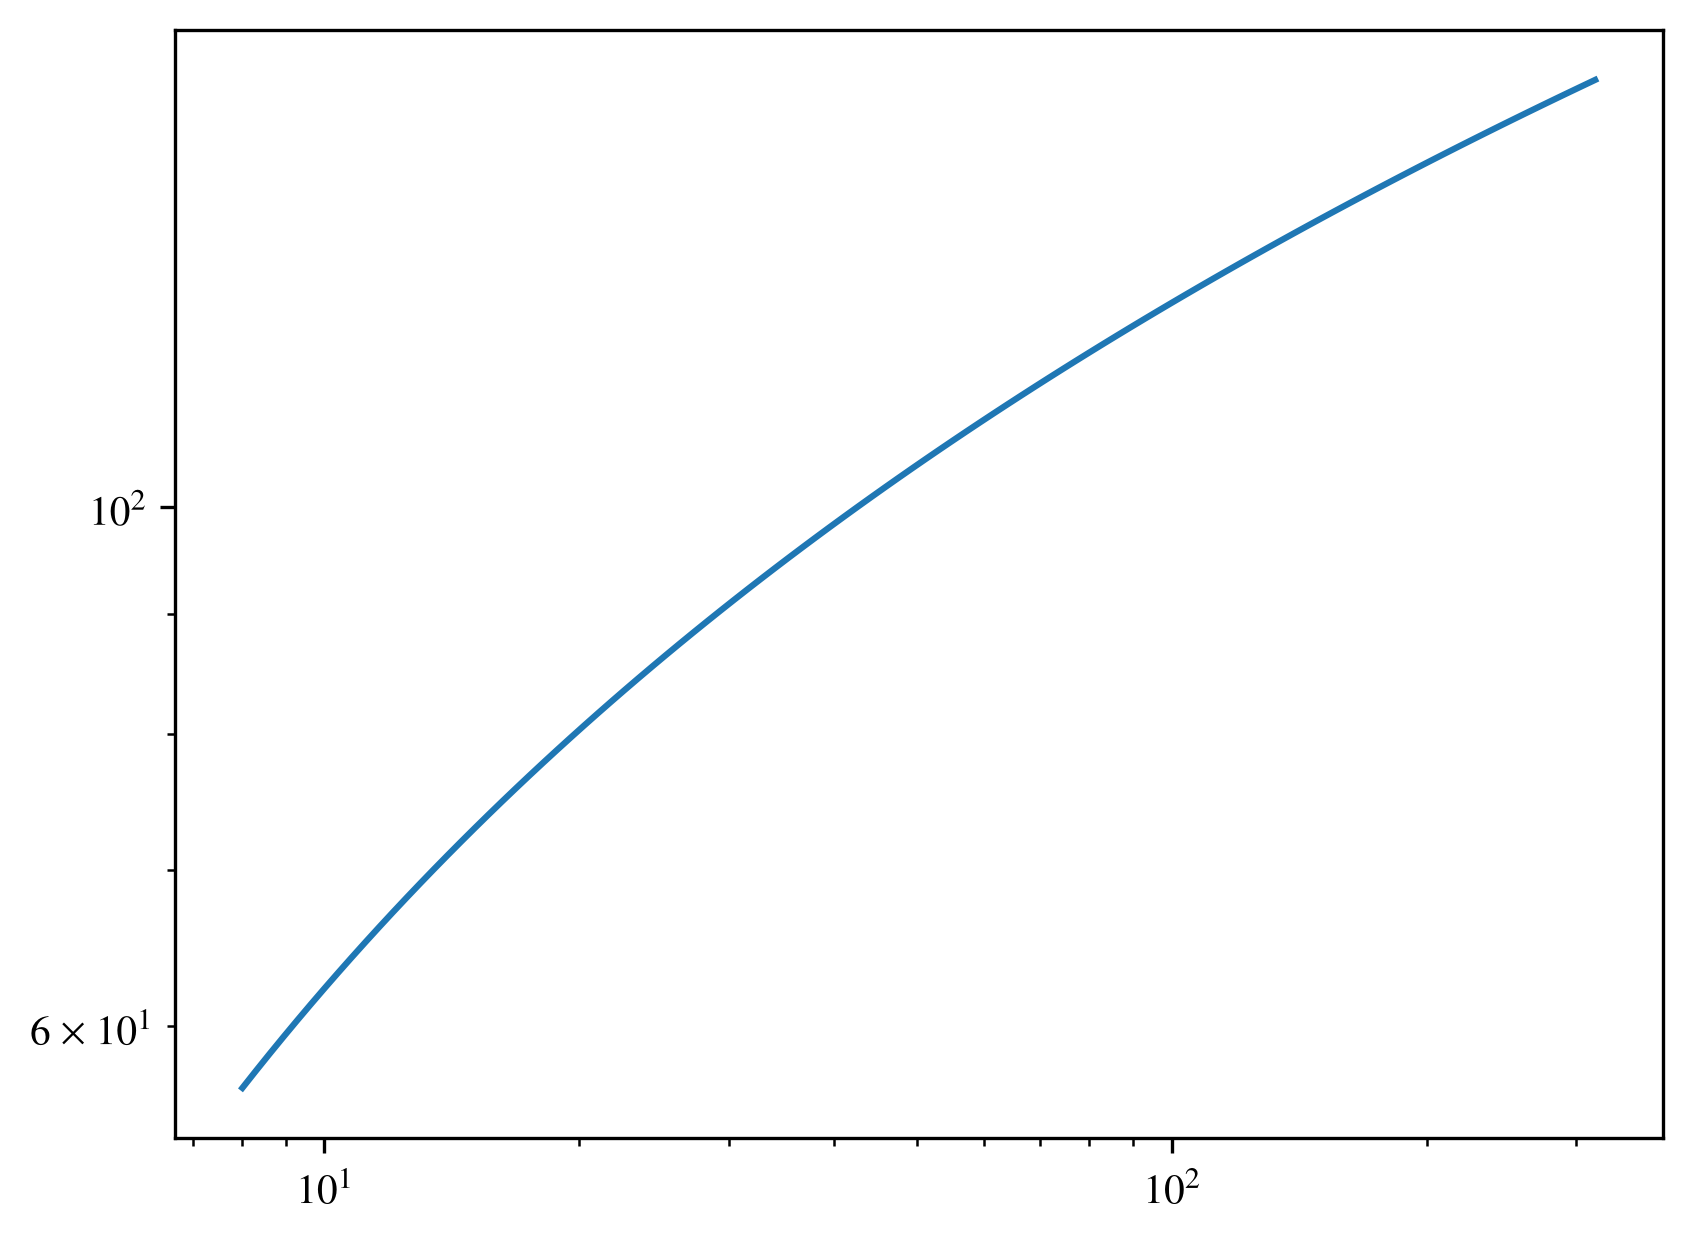

In [141]:
plt.loglog(rmaxes_new, ys_nircam_fit)

In [106]:
dlu.arcsec2rad(psf_pixel_scale/1e-6)*80

Array(10., dtype=float64)

In [33]:
psf10.max()

Array(10.30521492, dtype=float64)

In [34]:
psf11.max()

Array(10.33502939, dtype=float64)

In [24]:
psf10.shape

(1600, 1600)

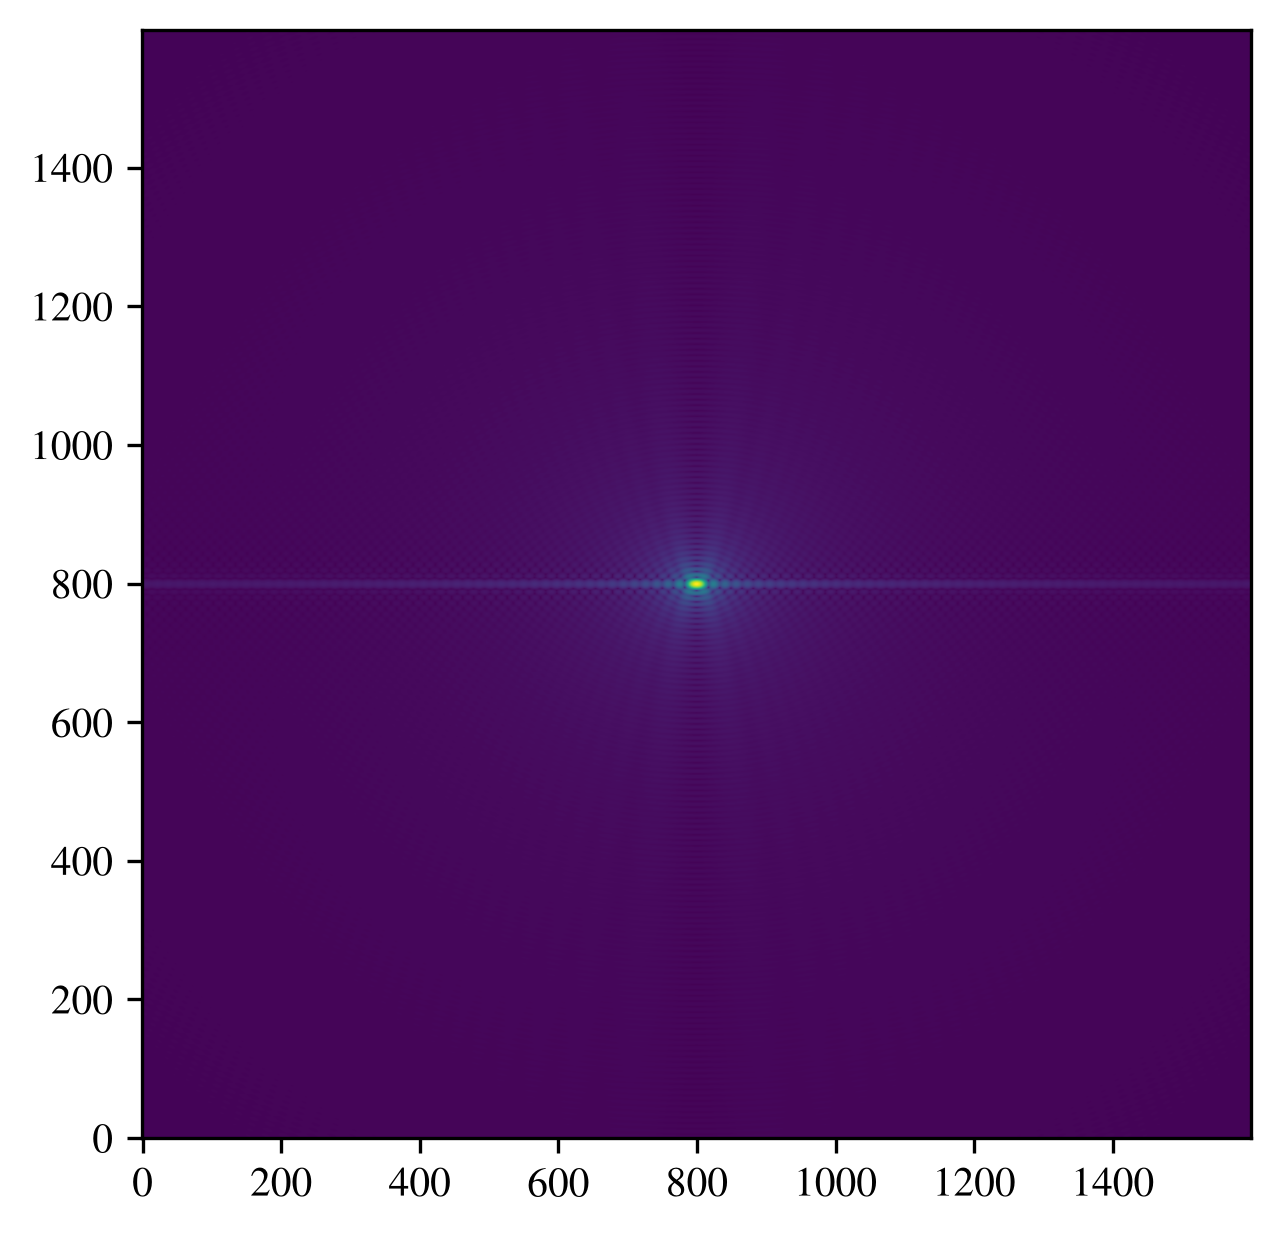

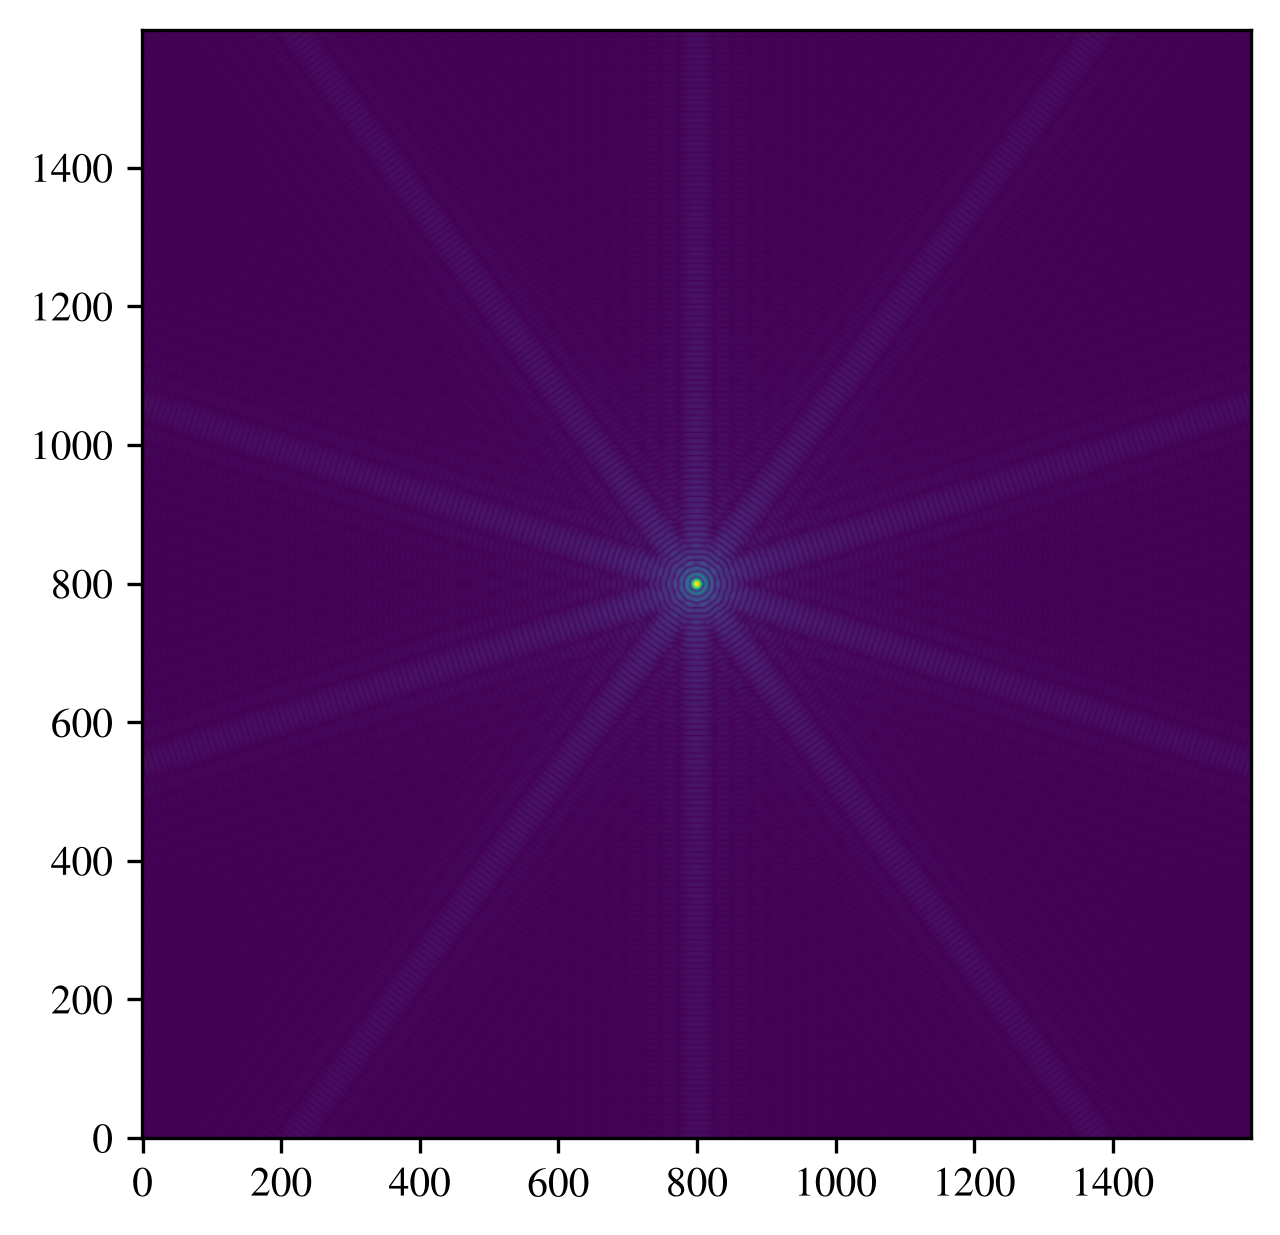

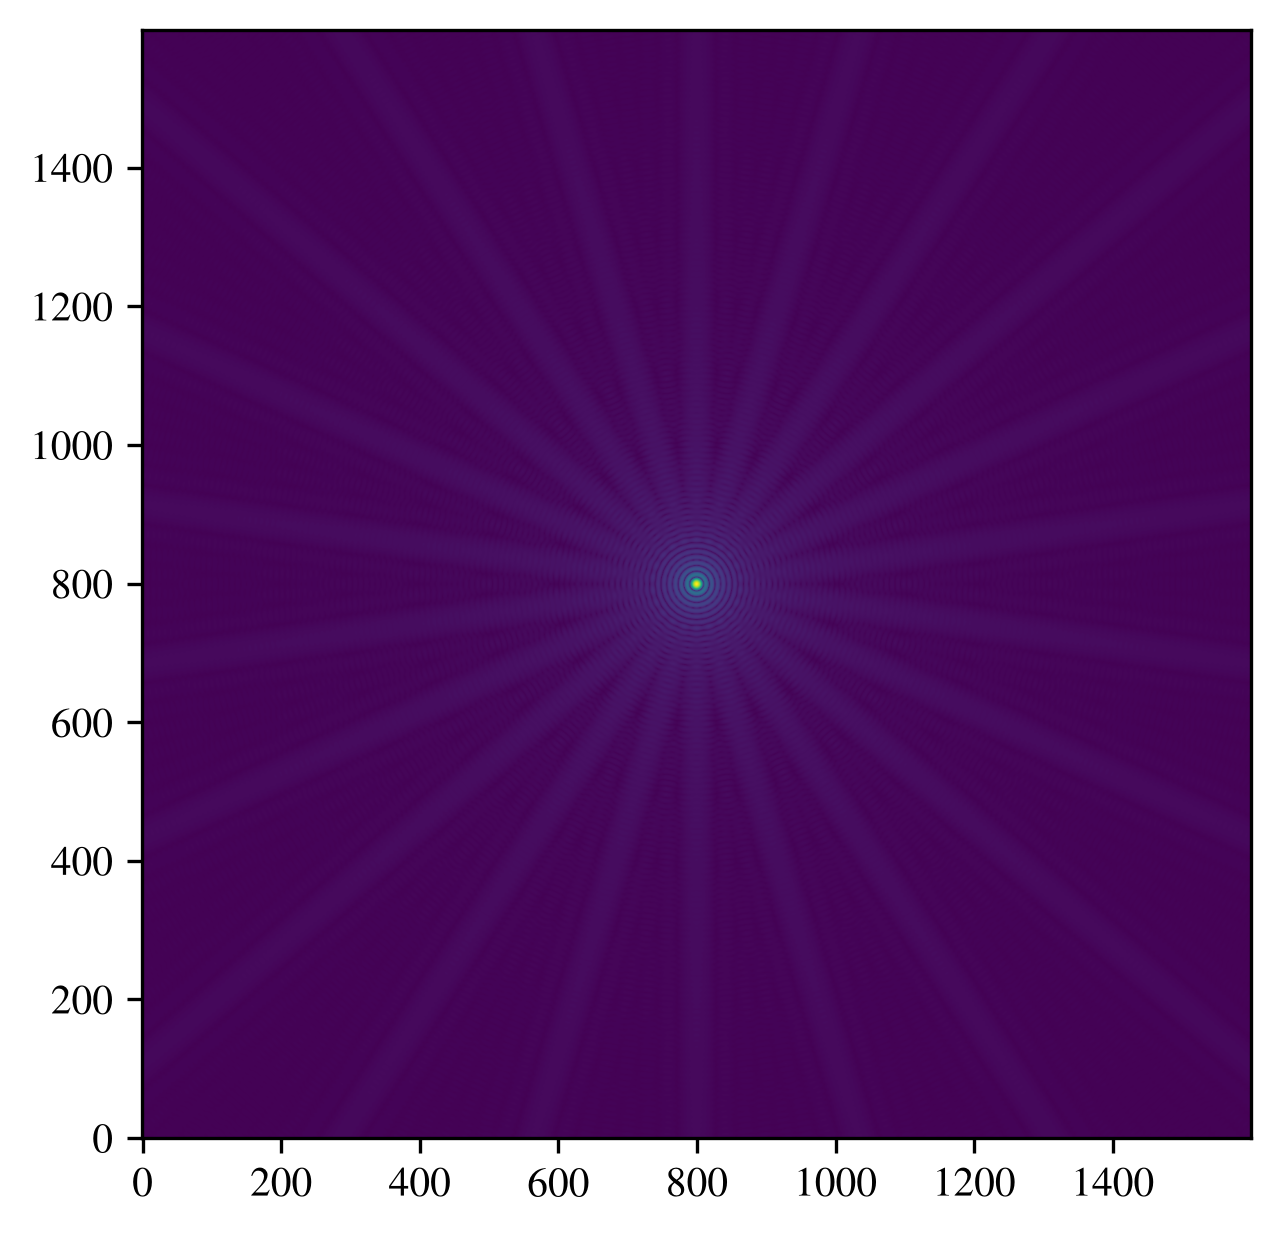

In [20]:
plt.imshow(telescope_square.model()**0.25)
plt.show()

plt.imshow(telescope_wfc3.model()**0.25)
plt.show()

plt.imshow(telescope_nircam.model()**0.25)
plt.show()

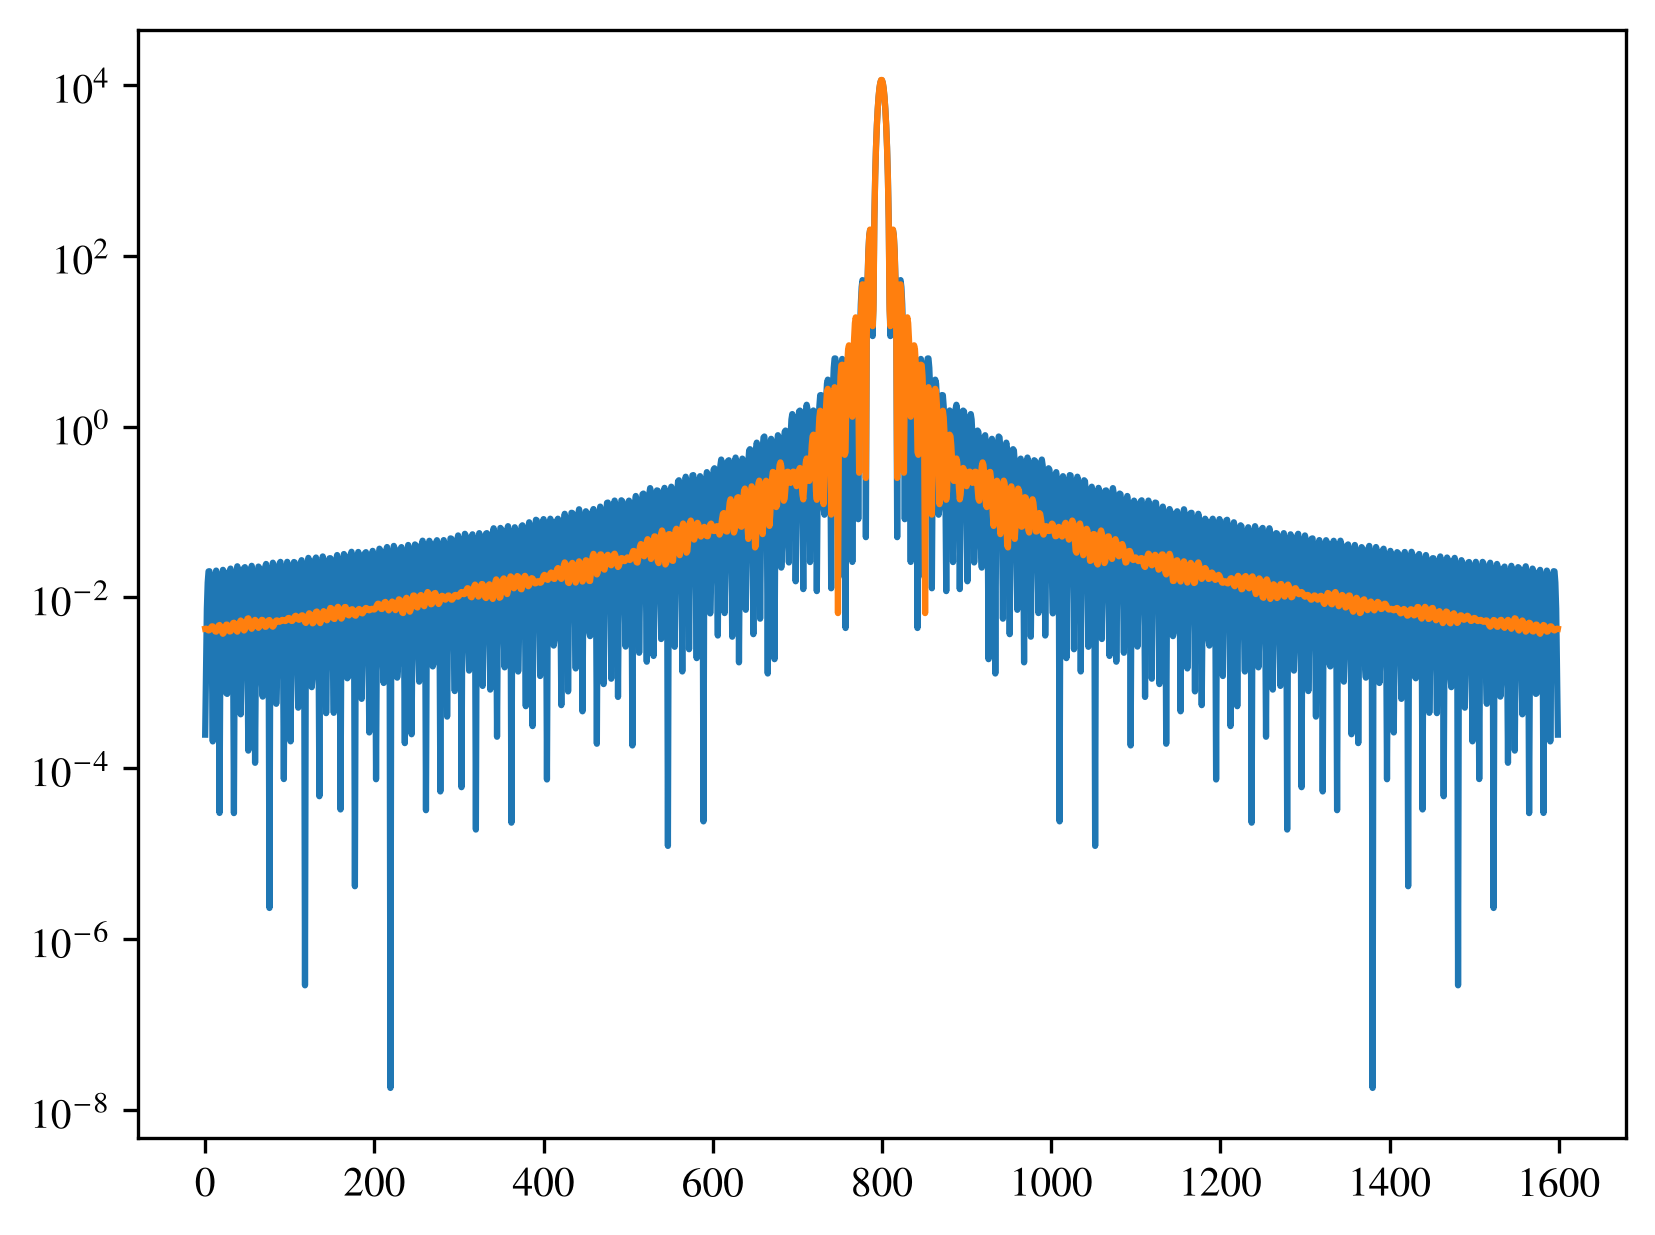

In [74]:
plt.plot(telescope_wfc3.model()[:,800]**1.0)
plt.plot(telescope_nircam.model()[:,800]**1.0)
plt.yscale('log')

plt.show()

In [ ]:
plt.rcParams['lines.dash_joinstyle'] = 'round'

In [326]:
ys_airy

Array([  3.10959723,   4.32003399,   6.03285936,   7.8039144 ,
         8.98165914,   9.61746021,   9.65237139,  10.1570896 ,
        12.41073068,  15.41586332,  17.56673205,  17.82907427,
        19.92940046,  24.31605288,  25.84383653,  27.95671779,
        33.2464402 ,  34.31699102,  40.72581175,  42.45309161,
        49.65987768,  53.34409716,  58.14157748,  65.94440481,
        73.58159714,  81.16603994,  89.41745646,  97.9324332 ,
       106.15455124, 118.35524338, 129.99566805, 144.55478219,
       157.85236834, 173.7750579 , 192.55705688, 210.03350353,
       233.06949053, 255.95184299, 281.69282399, 307.3958237 ,
       338.19160867, 372.3757292 , 409.85374689, 449.94678834,
       497.00142281, 545.49939935, 599.98185507, 657.17395629,
       721.74892961, 793.03657055], dtype=float64)

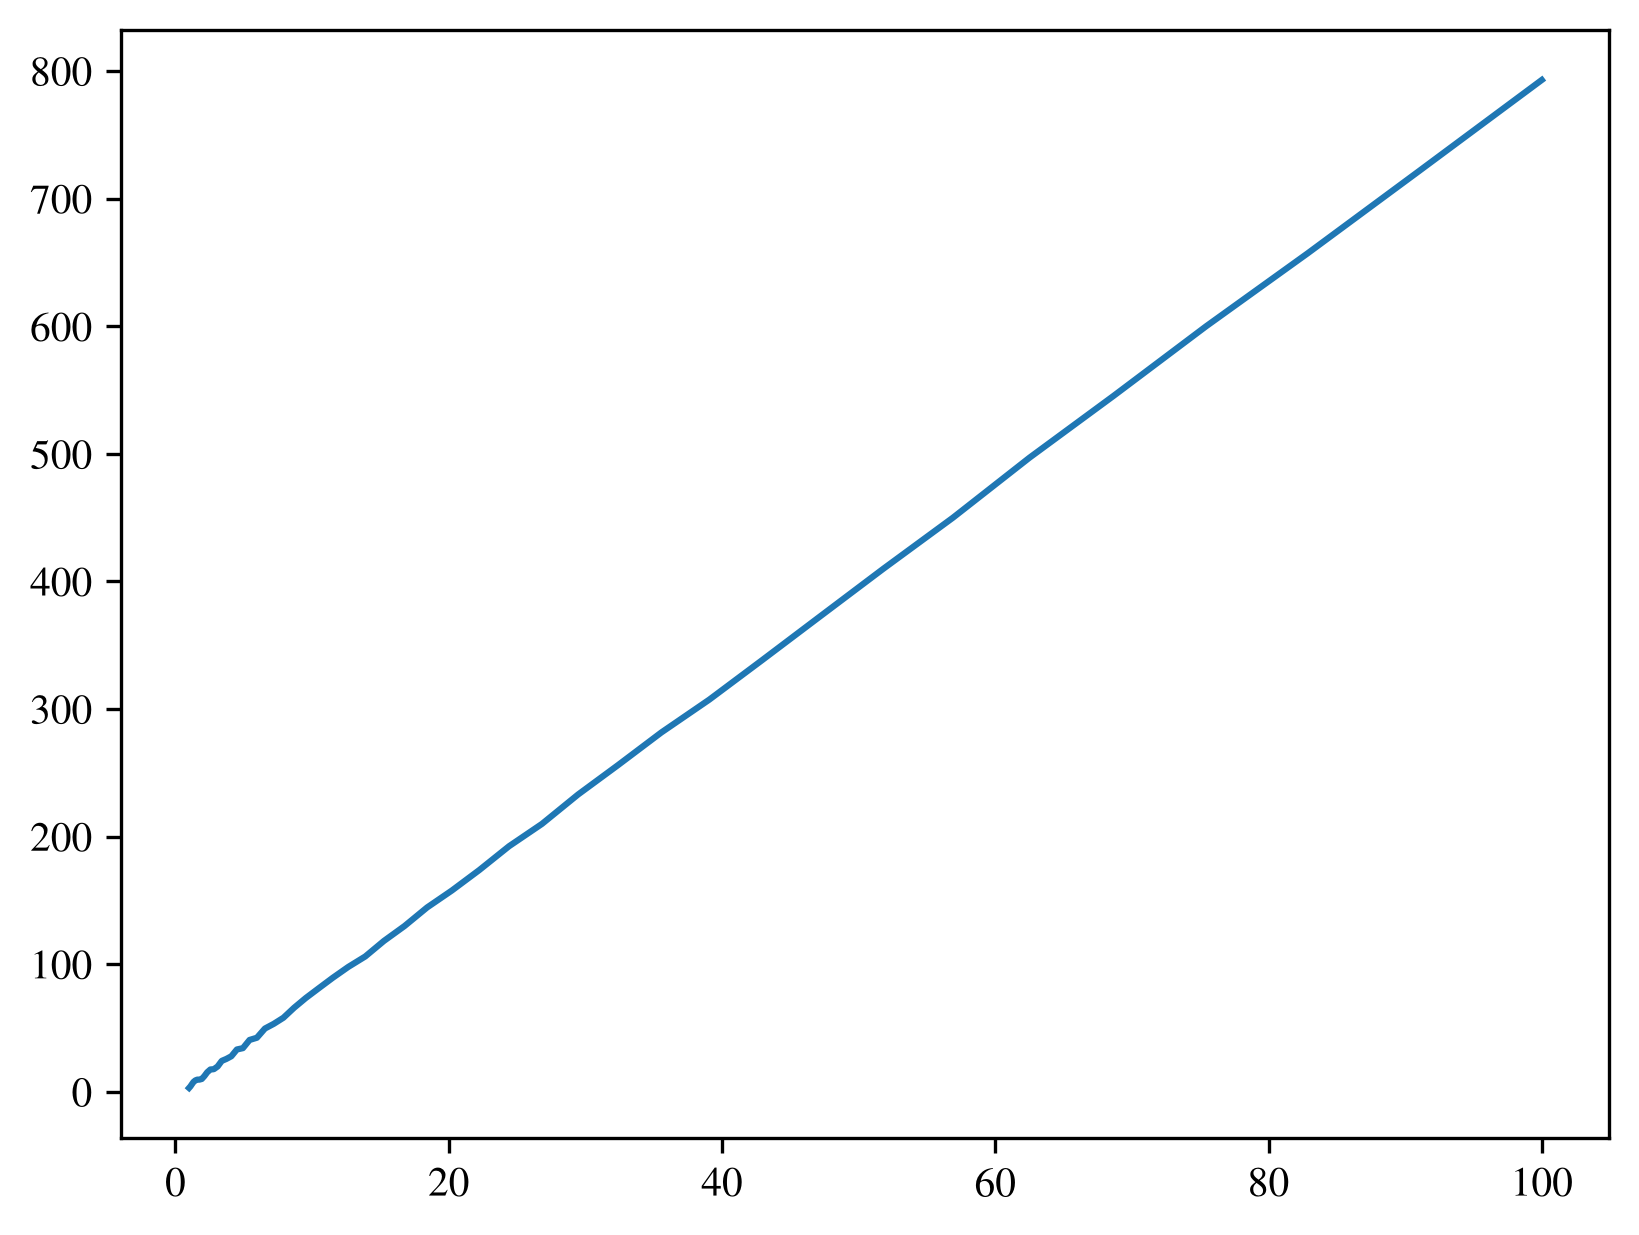

In [325]:
plt.plot(rmaxes, ys_airy)

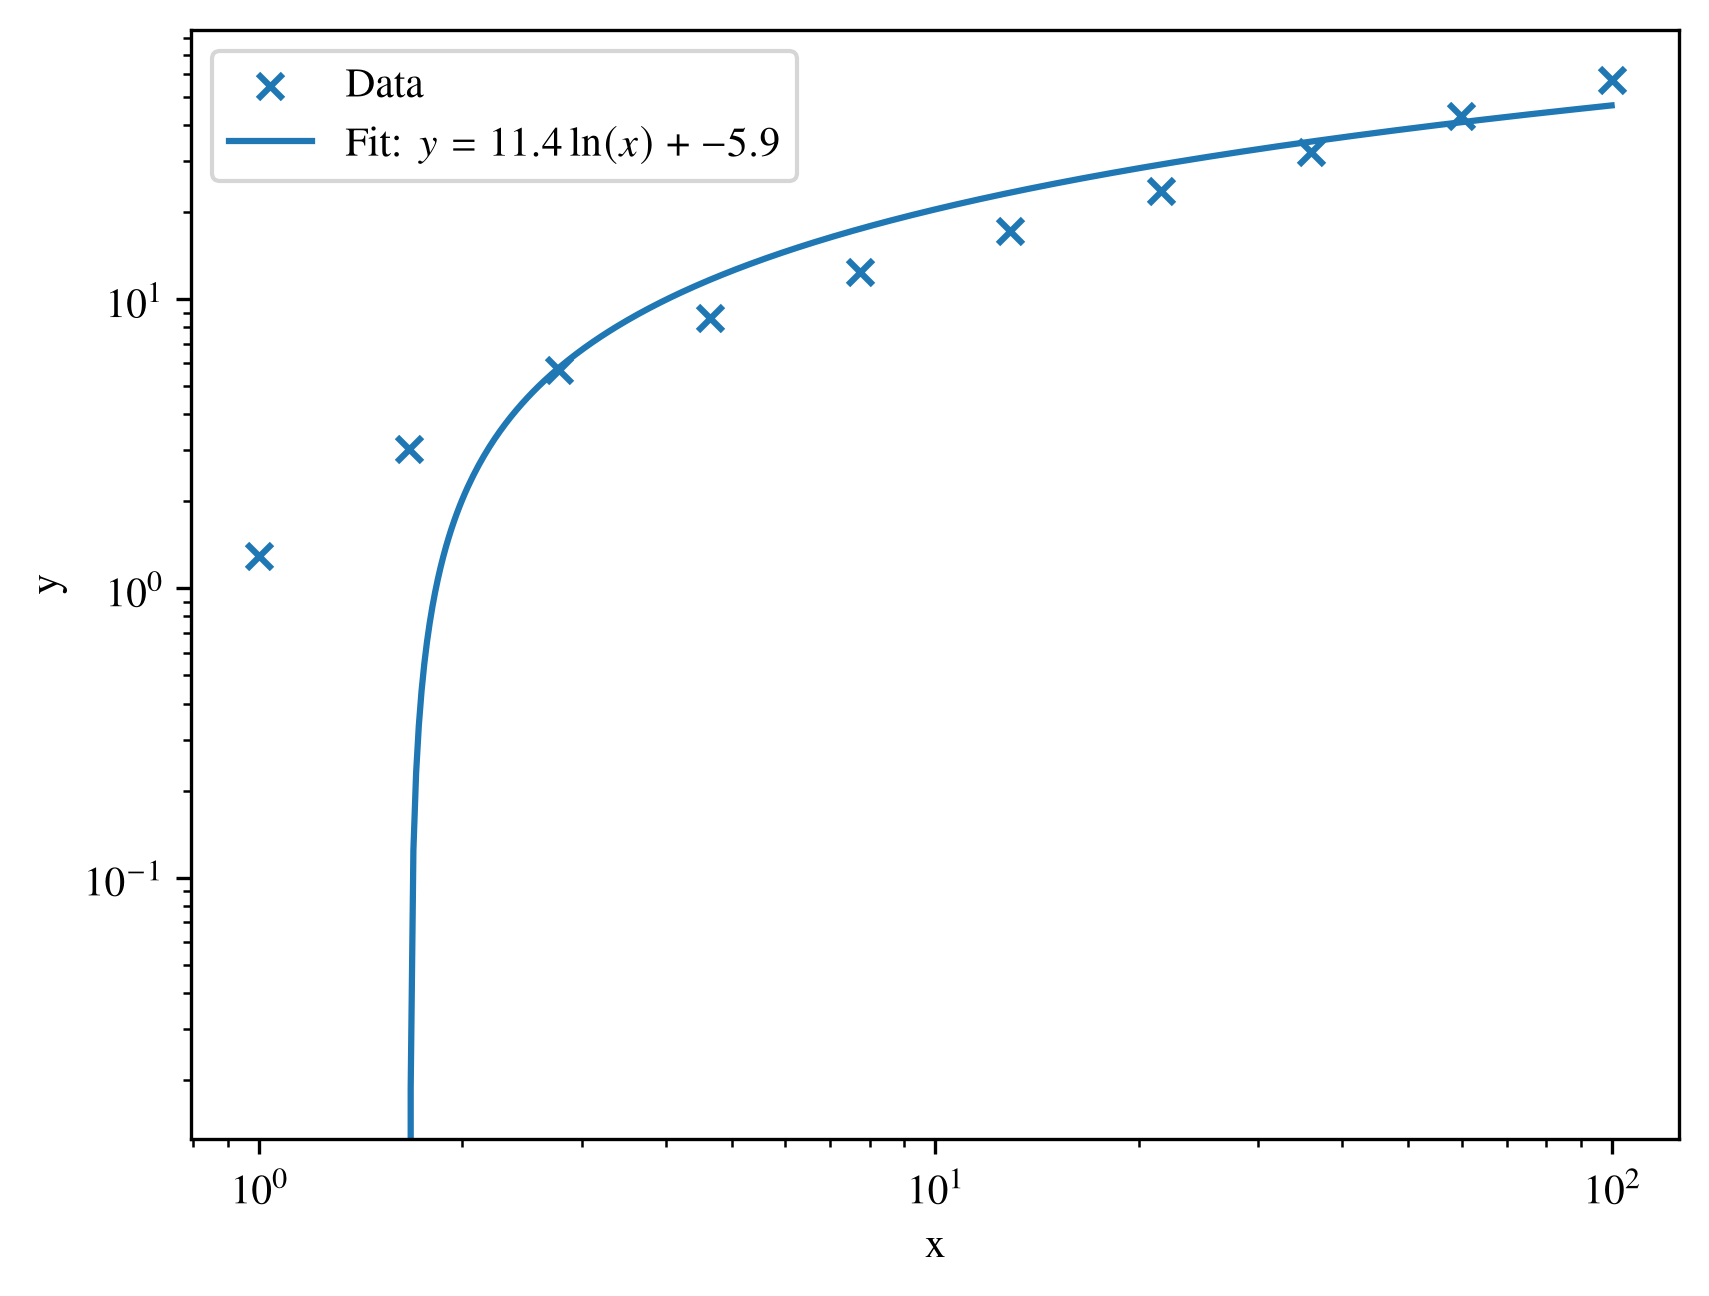

In [26]:
# fit logarithmic
A, B = np.polyfit(np.log(rmaxes), ys_square, 1)

# Smooth x-values for plotting the fitted curve
x_model = np.geomspace(rmaxes.min(), rmaxes.max(), 500)
y_model = A * np.log(x_model) + B

plt.scatter(rmaxes, ys_square, label="Data", marker='x')
plt.plot(x_model, y_model, label=fr"Fit: $y={A:.3g}\ln(x)+{B:.3g}$")
plt.xlabel("x")
plt.ylabel("y")
plt.yscale('log')
plt.xscale('log')
plt.legend()
plt.show()

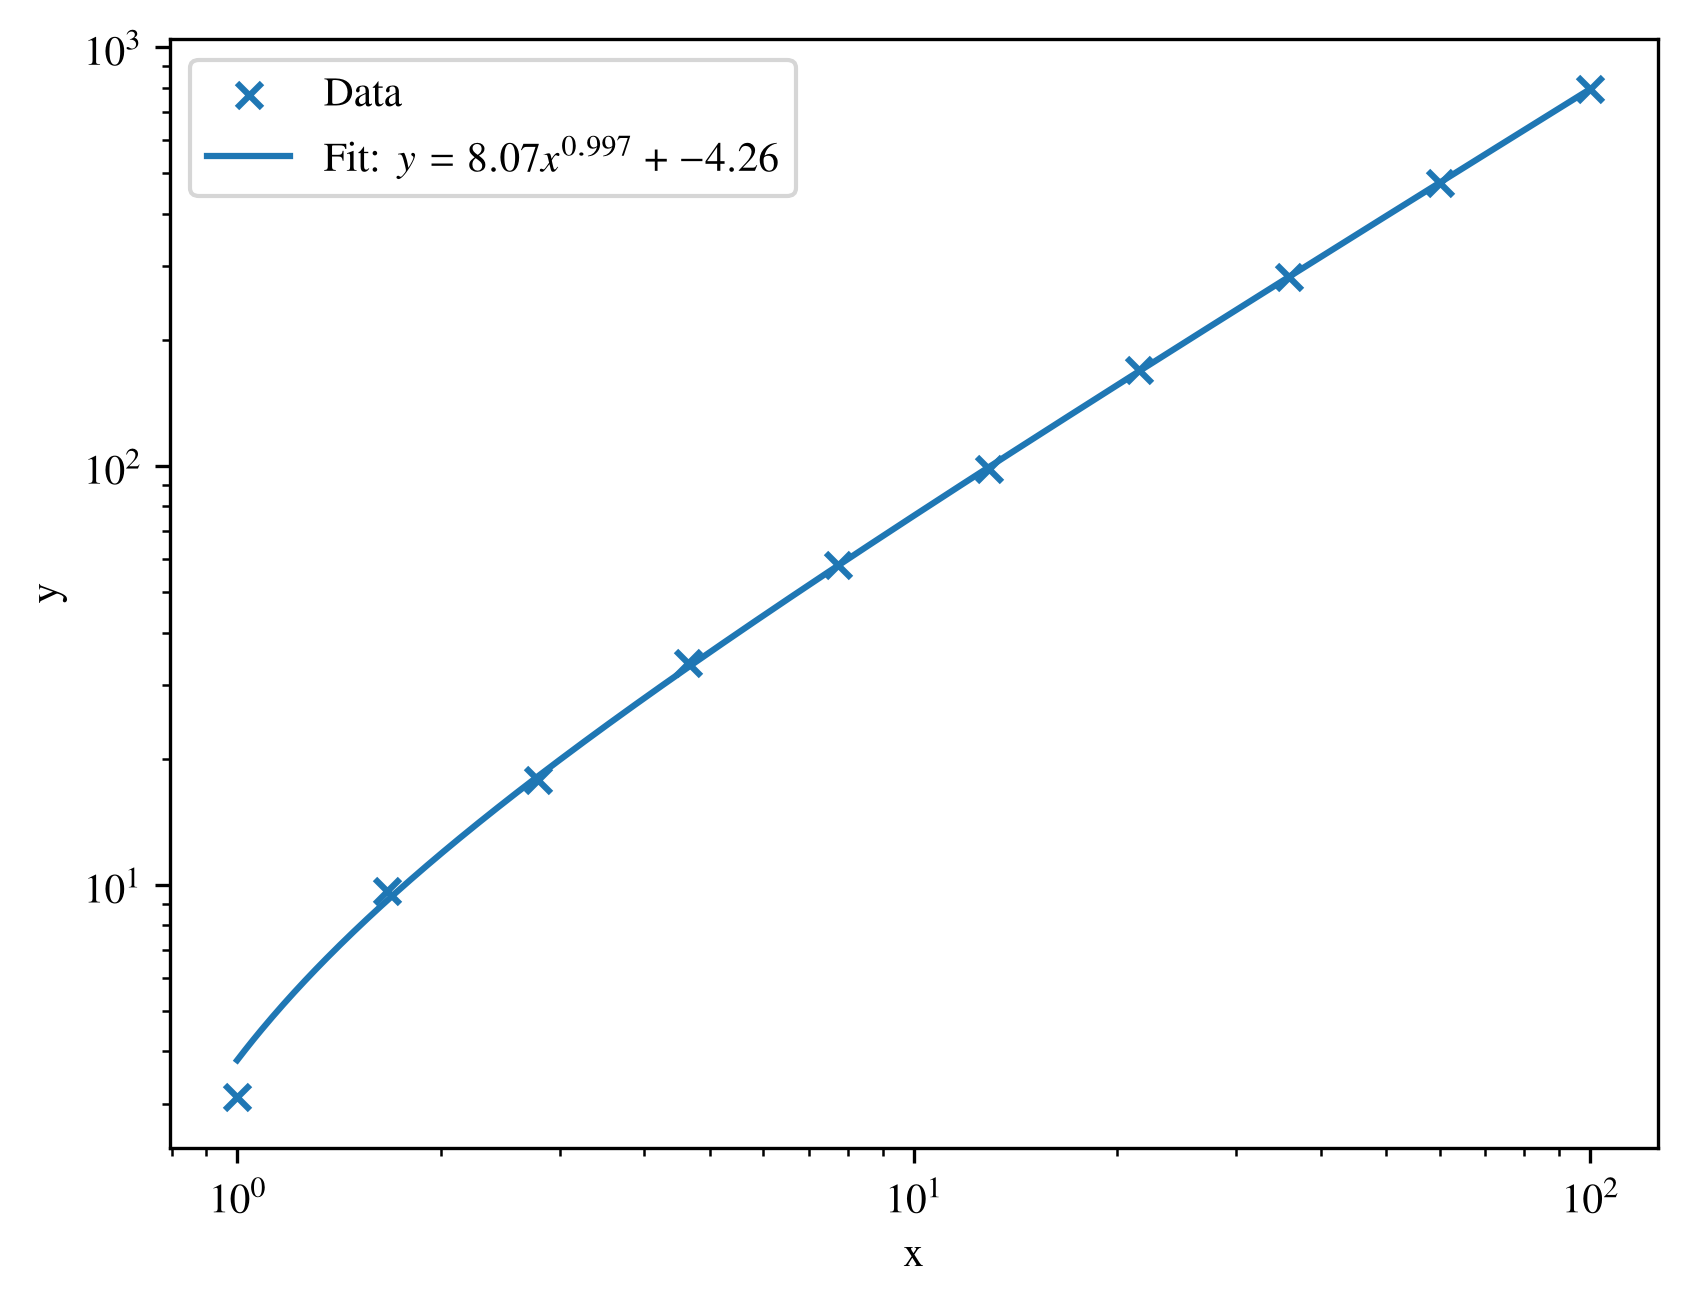

In [33]:
from scipy.optimize import curve_fit

def model(x, A, b, C):
    return A * x**b + C

# Fit
(A, b, C), _ = curve_fit(model, rmaxes, ys_airy)

# Smooth curve
x_model = np.geomspace(rmaxes.min(), rmaxes.max(), 500)
y_model = model(x_model, A, b, C)

plt.scatter(rmaxes, ys_airy, label="Data", marker='x')
plt.plot(x_model, y_model,
         label=fr"Fit: $y={A:.3g}x^{{{b:.3g}}}+{C:.3g}$")

plt.xscale('log')
plt.yscale('log')
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [297]:
m, log_A = np.polyfit(np.log(rmaxes[-5:]), np.log(ys_airy[-5:]), deg=1)
A = np.exp(log_A)

# y_fit = A * x**m

In [321]:
A, B = np.polyfit(rmaxes[-7:], ys_airy[-7:], deg=1)

In [322]:
A

Array(7.92663465, dtype=float64)

In [323]:
m

Array(0.99285248, dtype=float64)

In [324]:
B

Array(0.66573823, dtype=float64)

In [340]:
np.exp(np.mean(np.log(ys_nircam[-5:] / rmaxes[-5:])))

Array(5.60054601, dtype=float64)

In [231]:
ys_airy[:-30]

Array([ 3.10959723,  4.32003399,  6.03285936,  7.8039144 ,  8.98165914,
        9.61746021,  9.65237139, 10.1570896 , 12.41073068, 15.41586332,
       17.56673205, 17.82907427, 19.92940046, 24.31605288, 25.84383653,
       27.95671779, 33.2464402 , 34.31699102, 40.72581175, 42.45309161],      dtype=float64)

In [ ]:
ys_

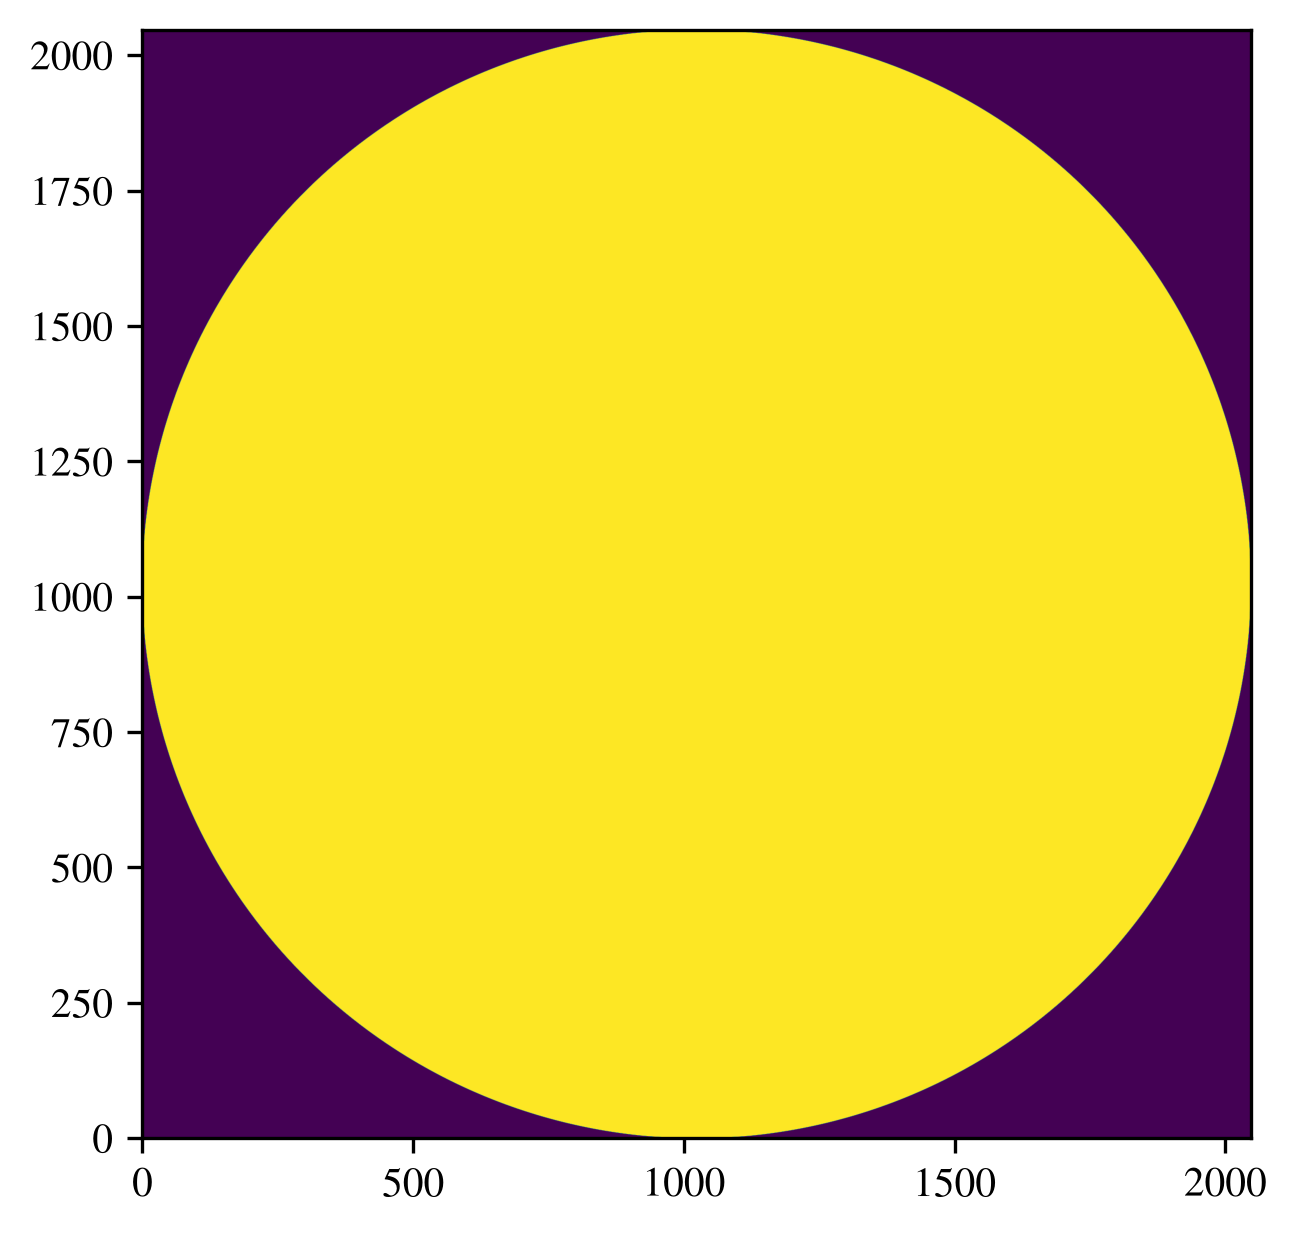

In [126]:
plt.imshow(aperture)

In [3]:
dlu.insert_layer()

TypeError: insert_layer() missing 4 required positional arguments: 'layers', 'layer', 'index', and 'allowed_type'

In [13]:
telescope

Telescope(
  optics=AngularOpticalSystem(
    wf_npixels=2048,
    diameter=1.0,
    layers={
      'aperture': TransmissiveLayer(transmission=f64[2048,2048], normalise=True)
    },
    psf_npixels=160,
    oversample=1,
    psf_pixel_scale=0.025783100780887046
  ),
  source=PointSource(
    spectrum=Spectrum(wavelengths=f64[1], weights=f64[1]),
    position=f64[2],
    flux=1000000.0
  ),
  detector=None
)

In [15]:
telescope.insert_layer(    (
        'aperture',
        dl.TransmissiveLayer(aperture, normalise=True)
    ),2)

AngularOpticalSystem(
  wf_npixels=2048,
  diameter=1.0,
  layers={
    'aperture_0': TransmissiveLayer(transmission=f64[2048,2048], normalise=True),
    'aperture_1': TransmissiveLayer(transmission=f64[2048,2048], normalise=True)
  },
  psf_npixels=160,
  oversample=1,
  psf_pixel_scale=0.025783100780887046
)

In [21]:
telescope.remove_layer(key='aperture')

AngularOpticalSystem(
  wf_npixels=2048,
  diameter=1.0,
  layers={},
  psf_npixels=160,
  oversample=1,
  psf_pixel_scale=0.025783100780887046
)